# P1 · Arrays primer: xarray, Zarr and rechunking

*A tool primer. It uses synthetic data, so it can be read before or alongside the project notebooks.*

Most data engineering is about tables: rows of records, columns of fields. Weather data is mostly not. A weather model's output, a satellite image or a reanalysis like ERA5 is an **array**: one number for every combination of time, latitude, longitude and often height. An hourly temperature field over a region for two years is a block of numbers 17,520 deep, 80 tall and 120 wide. You could flatten it into a table of 168 million rows, but you would lose what makes it useful: that neighbouring numbers are neighbours in space and time, and that most questions are about slices of the block ("this map at noon", "this point for two years").

This primer is about the three ideas that make working with such blocks practical:

1. **Labels.** Numbers in an array mean nothing without knowing which time and place each one is. *xarray* attaches names and coordinates to every dimension, so you write `sel(time="2023-07-15")` instead of remembering that time is axis 0 and July 15 is index 4,920.
2. **Chunks.** A big array is stored as many small pieces. *Zarr* is a storage format that keeps each piece as a separate compressed object, in a folder or a cloud bucket, so a reader can fetch only the pieces it needs.
3. **Layout.** Which pieces a reader needs depends on how the array was cut. A layout that is fast for one kind of reader is slow for another, and changing the layout of a large array (**rechunking**) is a real engineering problem.

We will use a synthetic temperature "cube" that behaves like the real thing, about 670 MB, big enough for the layout choices to show up in timings.

> **In ML terms.** An array dataset is a tensor with named axes and coordinate labels. Zarr is a sharded tensor store, one object per shard. Choosing chunk shapes is choosing a sharding scheme for your access pattern, the same problem as laying out embeddings or training examples for the reader that matters most.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import time, shutil, json
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from wxlab import synthetic

WORK = Path(DATA_DIR) / "primers" / "arrays"
shutil.rmtree(WORK, ignore_errors=True); WORK.mkdir(parents=True)

cube = synthetic.make_cube()          # 2 years, hourly, 80 x 120 grid
print(f"{cube.nbytes / 1e6:.0f} MB in memory")
cube

673 MB in memory


<xarray.Dataset> Size: 673MB
Dimensions:          (time: 17520, latitude: 80, longitude: 120)
Coordinates:
  * time             (time) datetime64[ns] 140kB 2023-01-01 ... 2024-12-30T23...
  * latitude         (latitude) float64 640B 42.0 41.85 41.7 ... 30.3 30.15 30.0
  * longitude        (longitude) float64 960B -125.0 -124.9 ... -110.1 -110.0
    elevation        (latitude, longitude) float32 38kB 494.8 434.7 ... 223.1
Data variables:
    air_temperature  (time, latitude, longitude) float32 673MB 8.284 ... 19.4
Attributes:
    title:    Synthetic hourly temperature cube
    source:   wxlab.synthetic.make_cube

## Part 1 · xarray: arrays with labels

The output above is an xarray **Dataset**: a collection of labelled arrays that share dimensions. Read it from the top.

- **Dimensions** are the named axes: `time` (17,520 hours), `latitude` (80) and `longitude` (120).
- **Coordinates** are the labels along each dimension: the actual timestamps, latitudes and longitudes. `elevation` is also a coordinate, but a two-dimensional one: it labels every grid point with its height. Coordinates do not have to be one-dimensional.
- **Data variables** are the measured quantities, here `air_temperature`. A single variable on its own is a **DataArray**.
- **Attributes** are free-form metadata such as units. Following the CF conventions (the community standard for climate and weather metadata) means any tool can read them.

### Selecting: by position or by label

`isel` selects by integer position, like NumPy. `sel` selects by coordinate value, which is what you usually want. `method="nearest"` picks the closest grid point to a location that is not exactly on the grid.

one map: {'latitude': 80, 'longitude': 120} | one point: {'time': 17520}
nearest grid point to San Francisco: 37.74683544303797 -122.3529411764706


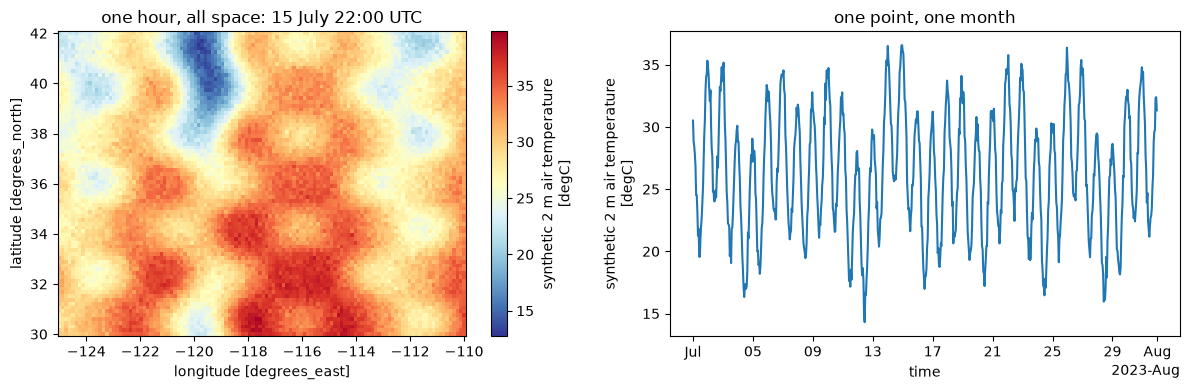

In [3]:
t = cube.air_temperature
first_hour = t.isel(time=0)                                   # by position
afternoon = t.sel(time="2023-07-15 22:00")                    # by label (UTC)
sf = t.sel(latitude=37.8, longitude=-122.4, method="nearest") # one point, all times
print("one map:", dict(afternoon.sizes), "| one point:", dict(sf.sizes))
print("nearest grid point to San Francisco:", float(sf.latitude), float(sf.longitude))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
afternoon.plot(ax=axes[0], cmap="RdYlBu_r")
axes[0].set_title("one hour, all space: 15 July 22:00 UTC")
sf.sel(time="2023-07").plot(ax=axes[1])
axes[1].set_title("one point, one month")
plt.tight_layout(); plt.show()

The map shows the structure built into the synthetic data: warmer in the south, a cold ridge of high ground running north to south, and the warm afternoon side of the daily cycle sweeping west with the sun. The time series shows the daily cycle and slower warm and cold spells.

**A classic trap: coordinate order.** Our latitudes run from north to south (42 down to 30), as they do in many real datasets including ERA5. A slice must follow the stored order, so `slice(35, 40)` selects nothing here and `slice(40, 35)` is correct. Nothing raises an error; you just get an empty result.

In [4]:
print("slice(35, 40):", t.sel(latitude=slice(35, 40)).sizes["latitude"], "rows")
print("slice(40, 35):", t.sel(latitude=slice(40, 35)).sizes["latitude"], "rows")

slice(35, 40): 0 rows
slice(40, 35): 33 rows


### Values at many points at once

Station work constantly needs "the grid value at each of these points". Passing coordinate arrays that share a new dimension name (here `station`) makes xarray pick one value per point instead of building every combination. This is called **vectorized** or pointwise indexing. `interp` does the same with linear interpolation between grid points instead of taking the nearest one.

In [5]:
rng = np.random.default_rng(0)
lats = xr.DataArray(rng.uniform(31, 41, 5), dims="station")
lons = xr.DataArray(rng.uniform(-124, -111, 5), dims="station")
at_noon = t.sel(time="2023-07-15 20:00")
nearest = at_noon.sel(latitude=lats, longitude=lons, method="nearest")
linear = at_noon.interp(latitude=lats, longitude=lons)
pd.DataFrame({"lat": lats.values.round(2), "lon": lons.values.round(2),
              "nearest": nearest.values.round(2), "interpolated": linear.values.round(2)})

,lat,lon,nearest,interpolated
0,37.37,-112.13,24.580000,23.59
1,33.70,-116.11,31.440001,30.96
2,31.41,-114.52,34.770000,34.09
3,31.17,-116.93,34.619999,34.40
4,39.13,-111.84,23.620001,24.47


### Computing along named dimensions

Reductions take dimension names, not axis numbers: `t.mean("time")` is the long-term average map. **groupby** splits along a coordinate and combines. Grouping by `time.hour` gives the average daily cycle; grouping by `time.month` gives the seasonal cycle. Together they give a **climatology**: what is normal for each place, month and hour. Subtracting it gives **anomalies**, the departures from normal, which is where weather (and sensor faults) live. **resample** changes the time resolution (hourly to daily), and **rolling** computes moving windows.

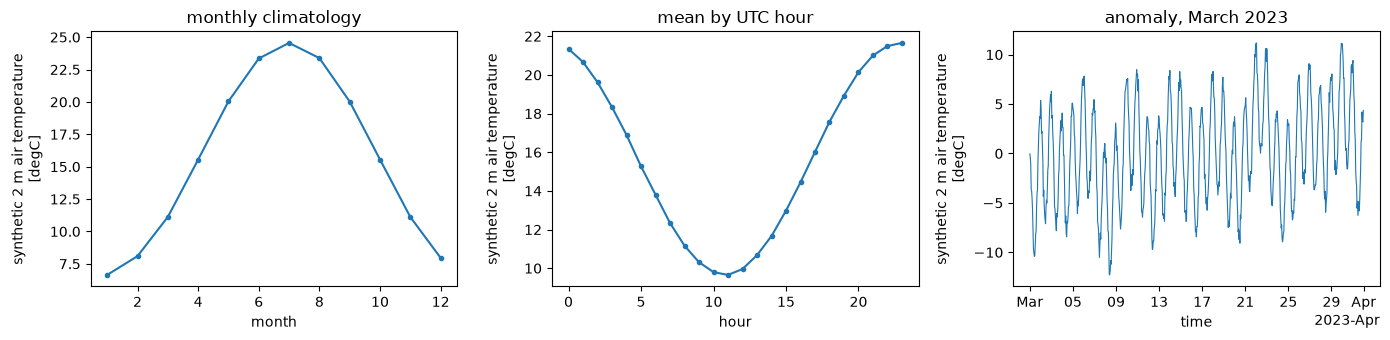

daily max over 2 years: 9.2 to 35.8 °C


In [6]:
point = t.sel(latitude=34.0, longitude=-116.5, method="nearest")       # a desert-like point
clim = point.groupby("time.month").mean()                             # seasonal cycle
by_hour = point.groupby("time.hour").mean()                            # daily cycle (UTC hours)
anomaly = point.groupby("time.month") - clim                           # departures from the monthly normal
daily_max = point.resample(time="1D").max()
smooth = point.rolling(time=24 * 7, center=True).mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
clim.plot(ax=axes[0], marker="."); axes[0].set_title("monthly climatology")
by_hour.plot(ax=axes[1], marker="."); axes[1].set_title("mean by UTC hour")
anomaly.sel(time="2023-03").plot(ax=axes[2], lw=0.8); axes[2].set_title("anomaly, March 2023")
plt.tight_layout(); plt.show()
print(f"daily max over 2 years: {float(daily_max.min()):.1f} to {float(daily_max.max()):.1f} °C")

Notice that the warmest hour is around 22–23 UTC: that is mid-afternoon local time at this longitude, about 7.8 hours behind UTC. Time zones are a frequent source of misread daily cycles.

### Weighted averages: grid boxes are not equal

On a latitude-longitude grid, boxes near the poles are much smaller than boxes at the equator, because lines of longitude converge. A plain average over the grid lets every box count equally, which over-weights the small high-latitude boxes. The fix, which WeatherBench 2 uses for every global score, is to weight each box by the cosine of its latitude, proportional to its area. xarray has this built in with `.weighted`.

In [7]:
weights = np.cos(np.deg2rad(cube.latitude))
plain = t.isel(time=slice(0, 24 * 30)).mean(("latitude", "longitude"))
area = t.isel(time=slice(0, 24 * 30)).weighted(weights).mean(("latitude", "longitude"))
print(f"first-month average: plain {float(plain.mean()):.3f} °C, area-weighted {float(area.mean()):.3f} °C")
print(f"weight of the northern edge relative to the southern edge: {float(weights[0] / weights[-1]):.2f}")

first-month average: plain 6.619 °C, area-weighted 6.729 °C
weight of the northern edge relative to the southern edge: 0.86


Over our small box (30–42 °N) the weights differ by only about 15%, so the two averages are close. Over the whole globe the poles would get almost no weight, and the difference between plain and weighted averages is several degrees.

> **In ML terms.** Area weights are importance weights on pixels, so a loss or a score reflects the surface of the planet rather than the pixel count. Several global weather models train with exactly this weighting in their loss.

## Part 2 · Lazy computation with dask

So far the cube has been in memory. Real datasets are not: ERA5 alone is petabytes. xarray handles this through **dask**, a library that splits an array into **chunks** and turns every operation into a graph of small tasks that only run when you ask for a result. Nothing is computed when you write the expression, which is why this is called **lazy** evaluation.

In [8]:
lazy = cube.chunk({"time": 24 * 7})            # one chunk per week, full space
expr = lazy.air_temperature.mean("time")       # builds a task graph, computes nothing
print(type(expr.data).__name__, "with", expr.data.npartitions, "output chunk(s);",
      len(dict(expr.data.__dask_graph__())), "tasks in the graph")
t0 = time.time(); result = expr.compute(); print(f"computed in {time.time() - t0:.2f}s")

Array with 1 output chunk(s); 247 tasks in the graph


computed in 0.31s


`chunk` cut the cube into 105 weekly pieces. The mean became a graph of tasks: average each piece, then combine the partial results. Calling `compute()` runs the graph, in parallel across cores. The same code would run on a cluster with a distributed scheduler, and on data that never fits in memory, because only a few chunks are in memory at once.

The chunk shape now starts to matter. A computation that needs the whole time series at one point has to touch every weekly chunk. Keep that in mind; Part 4 is about exactly this.

## Part 3 · Zarr: an array as many small objects

Zarr stores an array as a folder (or a bucket prefix) containing small JSON metadata documents and one compressed file per chunk. Because each chunk is its own object, many writers can write different chunks at the same time, and a reader can fetch only the chunks it needs, over a network, without reading a whole file. That is why Zarr became the standard format for analysis-ready weather data in the cloud (ARCO-ERA5 and WeatherBench 2 both use it).

We write the cube in a **training layout**: each chunk holds one day of hours for the whole grid. A training job that reads maps at a few times reads few chunks. We compress each chunk with Blosc using the zstd algorithm, a fast, common choice for floating-point fields.

In [9]:
import zarr

train_store = WORK / "train.zarr"
encoding = {"air_temperature": {
    "chunks": (24, 80, 120),
    "compressors": [zarr.codecs.BloscCodec(cname="zstd", clevel=3, shuffle="bitshuffle")],
}}
t0 = time.time()
cube.to_zarr(train_store, mode="w", encoding=encoding, zarr_format=3, consolidated=True)
print(f"written in {time.time() - t0:.1f}s")

files = [p for p in train_store.rglob("*") if p.is_file()]
chunk_files = [p for p in files if "/air_temperature/c/" in str(p)]
on_disk = sum(p.stat().st_size for p in chunk_files)
print(f"{len(files)} files in the store, {len(chunk_files)} of them chunks of air_temperature")
print(f"air_temperature: {cube.air_temperature.nbytes / 1e6:.0f} MB raw, {on_disk / 1e6:.0f} MB on disk "
      f"(compression ratio {cube.air_temperature.nbytes / on_disk:.1f}x)")
print("example chunk keys:", sorted(str(p.relative_to(train_store)) for p in chunk_files)[:3])

written in 0.8s
740 files in the store, 730 of them chunks of air_temperature
air_temperature: 673 MB raw, 512 MB on disk (compression ratio 1.3x)
example chunk keys: ['air_temperature/c/0/0/0', 'air_temperature/c/1/0/0', 'air_temperature/c/10/0/0']


/Users/ashu/Workspace/weather-data-lab/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


There is one chunk per day (730), each named by its position in the chunk grid: `c/0/0/0` is the first day, `c/1/0/0` the second.

The compression ratio is modest because the synthetic cube contains random noise, and noise does not compress. Smooth real fields compress better, and many archives also round values to the precision the instrument or model actually has before compressing, which helps a lot. Measuring the ratio on your own data, per variable, is part of estimating storage cost. The metadata lives in small `zarr.json` documents. Here is the part that describes the temperature array:

In [10]:
meta = json.loads((train_store / "air_temperature" / "zarr.json").read_text())
{k: meta[k] for k in ["shape", "data_type", "chunk_grid", "fill_value", "codecs"]}

{'shape': [17520, 80, 120],
 'data_type': 'float32',
 'chunk_grid': {'name': 'regular',
  'configuration': {'chunk_shape': [24, 80, 120]}},
 'fill_value': 'NaN',
 'codecs': [{'name': 'bytes', 'configuration': {'endian': 'little'}},
  {'name': 'blosc',
   'configuration': {'typesize': 4,
    'cname': 'zstd',
    'clevel': 3,
    'shuffle': 'bitshuffle',
    'blocksize': 0}}]}

Everything a reader needs is in that document: the shape, the data type, the chunk shape, the **fill value** (what to return for a chunk that does not exist) and the chain of **codecs** that turn bytes on disk into numbers (here: bytes in little-endian order, then Blosc compression).

### Reading lazily

`xr.open_zarr` reads only the metadata. The result looks like the cube, but every variable is a dask array backed by the chunks on disk; data is read only when needed.

In [11]:
stored = xr.open_zarr(train_store)
t0 = time.time(); one_map = stored.air_temperature.sel(time="2023-07-15 22:00").load()
print(f"one map: {time.time() - t0:.3f}s")
print("chunks of the lazy array:", stored.air_temperature.data.chunksize)

one map: 0.006s
chunks of the lazy array: (24, 80, 120)


### Growing a store: append and region writes

Real stores grow every day as new data arrives. Two patterns cover most pipelines.

**Append** adds data along a dimension, usually time. It is simple, but appends must happen in order and one at a time.

**Region writes** first create the whole store's metadata (a *template*, with no data), then let independent workers each write their own slice. Each write is **idempotent**: rewriting a day produces the same bytes, so retries and reruns are safe, and days can be written in any order or in parallel. This is how large datasets like ARCO-ERA5 are built.

In [12]:
small = cube.isel(time=slice(0, 24 * 10)).drop_vars("elevation")

# Append: write 9 days, then add the 10th.
app = WORK / "append.zarr"
small.isel(time=slice(0, 24 * 9)).to_zarr(app, mode="w", zarr_format=3)
small.isel(time=slice(24 * 9, None)).to_zarr(app, append_dim="time")
print("after append:", xr.open_zarr(app).sizes["time"], "hours")

# Region writes: template first, then days in any order.
reg = WORK / "regions.zarr"
small.to_zarr(reg, mode="w", compute=False, zarr_format=3,
              encoding={"air_temperature": {"chunks": (24, 80, 120)}})       # metadata only
for day in [7, 2, 9, 0, 5, 1, 8, 3, 6, 4, 2]:                             # shuffled, day 2 written twice
    part = small.isel(time=slice(24 * day, 24 * (day + 1))).drop_vars(["latitude", "longitude"])
    part.to_zarr(reg, region={"time": slice(24 * day, 24 * (day + 1))})
same = np.array_equal(xr.open_zarr(reg).air_temperature.values, small.air_temperature.values)
print("region-written store equals the source:", same)

/Users/ashu/Workspace/weather-data-lab/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/ashu/Workspace/weather-data-lab/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/ashu/Workspace/weather-data-lab/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


after append: 240 hours


region-written store equals the source: True


### The silent failure: a missing chunk

Here is the most dangerous property of chunked storage. If a chunk is missing, because a write failed or a file was lost, Zarr does not raise an error. It returns the fill value for that region, which for floating-point data is NaN, and the dataset still looks complete. Below we delete one chunk and read the store back.

In [13]:
victim = reg / "air_temperature" / "c" / "4" / "0" / "0"
victim.unlink()
reread = xr.open_zarr(reg).air_temperature
print("read without error; missing values:", int(reread.isnull().sum()), "of", reread.size)

def missing_chunks(store, var, shape, chunks):
    """Compare the chunk keys a complete array must have with the keys present on disk."""
    grid = [range(int(np.ceil(s / c))) for s, c in zip(shape, chunks)]
    expected = {"/".join(map(str, idx)) for idx in np.ndindex(*[len(g) for g in grid])}
    root = Path(store) / var / "c"
    present = {str(p.relative_to(root)) for p in root.rglob("*") if p.is_file()}
    return sorted(expected - present)

print("missing chunk keys:", missing_chunks(reg, "air_temperature", reread.shape, (24, 80, 120)))

read without error; missing values: 230400 of 2304000
missing chunk keys: ['4/0/0']


The read succeeded and simply contained a day of NaNs. In a training pipeline that day would be silently dropped or, worse, filled with zeros by a later step. The defence is a **completeness check** that compares the chunk keys a complete array must have with the keys present, run after every write. A manifest of expected outputs, checked at the end of a job, is the general form of this idea.

**Sharding.** Very small chunks mean very many objects, and object stores charge per request. Zarr 3 adds **sharding**: many logical chunks packed into one stored object with an index, so readers still fetch small pieces (by byte range) while the store holds far fewer files.

## Part 4 · Layout: the chunk shape must match the reader

Two readers want very different things from the same cube.

- A **training job** reads whole maps at a few times. With daily chunks, one map needs 1 chunk.
- A **quality check** reads the full time series at one point. With daily chunks, it needs all 730 chunks, decompressing about 670 MB to use 70 KB.

The opposite layout, chunks that are long in time and small in space, reverses the costs. Below we build that **analysis layout** (all hours, 10 × 10 tiles) and time both readers on both layouts, reading through Zarr directly so dask is not involved.

In [14]:
analysis_store = WORK / "analysis.zarr"
t0 = time.time()
(xr.open_zarr(train_store).drop_vars("elevation")   # keep only the 3-D field
   .chunk({"time": -1, "latitude": 10, "longitude": 10})
   .to_zarr(analysis_store, mode="w", zarr_format=3,
            encoding={"air_temperature": {"chunks": (17520, 10, 10)}}))
print(f"rechunked in {time.time() - t0:.1f}s")

def timed(fn, repeat=3):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

rows = []
for name, store in [("training (24, 80, 120)", train_store), ("analysis (17520, 10, 10)", analysis_store)]:
    arr = zarr.open_array(store / "air_temperature", mode="r")
    rows.append({"layout": name,
                 "one map (s)": timed(lambda: arr[5000, :, :]),
                 "one point, 2 years (s)": timed(lambda: arr[:, 40, 60])})
pd.DataFrame(rows).set_index("layout").round(4)

/Users/ashu/Workspace/weather-data-lab/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


rechunked in 1.6s


,one map (s),"one point, 2 years (s)"
layout,,
"training (24, 80, 120)",0.0033,0.272
"analysis (17520, 10, 10)",0.1709,0.007


The table is the whole argument for caring about layout. Each layout is fast for the reader it was designed for and one to two orders of magnitude slower for the other. On a laptop the difference is fractions of a second; on a petabyte dataset in cloud storage it is the difference between a QA job that costs dollars and one that costs thousands, because every unnecessary chunk is a network request and bytes to decompress.

The usual answer is to **keep two copies**: a primary store in the layout of the main consumer (training) and a rechunked copy for analysis, rebuilt when the primary changes. Storage is cheap compared with reading the wrong layout repeatedly.

### Why rechunking a large array is hard

The rechunk above was a single dask command, and on 670 MB it just works. Look at what it asks for, though: every output chunk (all hours for one 10 × 10 tile) needs a piece of *every* input chunk (all 730 days). Each worker has to gather data from everywhere, and on a large array that means either enormous memory or enormous numbers of small reads. This all-to-all pattern is the same **shuffle** that makes joins expensive in table engines.

The standard trick, used by the *rechunker* library and by xarray-beam, is to go through an **intermediate layout**, chosen so that both steps are cheap and memory per task stays under a limit. Below: from daily maps, first to monthly blocks of quarter-size tiles, then to the final tiles.

In [15]:
inter_store, final_store = WORK / "intermediate.zarr", WORK / "analysis_two_step.zarr"
t0 = time.time()
(xr.open_zarr(train_store).drop_vars("elevation").chunk({"time": 24 * 30, "latitude": 40, "longitude": 60})
   .to_zarr(inter_store, mode="w", zarr_format=3,
            encoding={"air_temperature": {"chunks": (720, 40, 60)}}))
(xr.open_zarr(inter_store).chunk({"time": -1, "latitude": 10, "longitude": 10})
   .to_zarr(final_store, mode="w", zarr_format=3,
            encoding={"air_temperature": {"chunks": (17520, 10, 10)}}))
print(f"two-step rechunk in {time.time() - t0:.1f}s")
same = np.array_equal(zarr.open_array(final_store / "air_temperature")[:, 40, 60],
                      zarr.open_array(analysis_store / "air_temperature")[:, 40, 60])
print("same result as the direct rechunk:", same)
mb = lambda c: np.prod(c) * 4 / 1e6
print(f"chunk sizes: input {mb((24, 80, 120)):.1f} MB, intermediate {mb((720, 40, 60)):.1f} MB, output {mb((17520, 10, 10)):.1f} MB")

/Users/ashu/Workspace/weather-data-lab/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


/Users/ashu/Workspace/weather-data-lab/.venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


two-step rechunk in 2.5s
same result as the direct rechunk: True
chunk sizes: input 0.9 MB, intermediate 6.9 MB, output 7.0 MB


Each step now reads a modest number of inputs per output chunk, and the intermediate store absorbs the all-to-all pattern. At this size the two-step version is not faster, because everything fits in memory anyway. At terabyte scale it is the difference between a job that runs and one that runs out of memory.

The **rechunker** library automates choosing the intermediate layout from a memory limit. At the time of writing it supports only the older Zarr format (version 2): its compatibility issues with Zarr 3 are still open. The maintained ways to rechunk large arrays today are dask (as above) and xarray-beam's `Rechunk`, which the pipelines primer (P2) covers.

## Where this shows up in the project

Notebook 03 opens every HRRR file as an xarray Dataset and picks values at station points with exactly the pointwise selection from Part 1. Notebook 11 repeats Parts 3 and 4 on four years of real HRRR data over California, where the layout costs are larger and real.

## What surprised me

**Labels prevent a whole class of bugs**, but not all of them: a slice in the wrong direction silently returns nothing.

**A missing chunk is not an error.** Chunked stores fail quietly, so completeness has to be checked explicitly, after every write.

**Layout matters more than compute.** The same data, read by the same code, differs by orders of magnitude in cost depending on how it was cut, and the only fix is to store it the way it will be read, sometimes twice.

**The best-known rechunking tool is stuck on the old format.** Library ecosystems move unevenly; checking what is actually maintained is part of choosing a tool.

## Check yourself

<details><summary>Why does <code>t.sel(latitude=slice(35, 40))</code> return nothing for our cube?</summary>
Latitudes are stored from north to south (42 down to 30), and a slice must follow the stored order. Use <code>slice(40, 35)</code>, or sort the coordinate first.
</details>

<details><summary>A QA job reads 10 years of hourly data at 5,000 station points from a store chunked as (24 hours, whole globe). Roughly how many chunks does it read, and what would you change?</summary>
Every daily chunk, about 3,650 per variable, each containing the whole globe, to use a tiny fraction of each. Build an analysis copy chunked long in time and small in space, so each station's series sits in one or a few chunks.
</details>

<details><summary>Why are region writes safer than appends for a large backfill?</summary>
Each region write is independent and idempotent: workers can write different days in parallel and in any order, and a failed day can be rewritten without touching the rest. Appends must run one at a time, in order, and a failure in the middle leaves the store in a state that is awkward to repair.
</details>

<details><summary>Why is a missing Zarr chunk more dangerous than a missing file?</summary>
A missing file usually raises an error when it is opened. A missing chunk silently reads as the fill value, so the dataset looks complete. Only an explicit check of expected against present chunks catches it.
</details>

> **In a design discussion.** "How would you chunk this dataset?" has no single answer; the right answer starts with "who reads it, and how?". Name the two layouts, estimate chunk sizes (aim for roughly 10–100 MB per chunk), mention a rechunked copy for analysis, sharding to keep object counts down, and a completeness manifest checked after every write.